# ۱۳ · از R-CNN تا YOLO و SSD؛ تشخیص شیء به زبان ساده

تاریخچه و تفاوت پنج خانواده را می‌خوانیم، کادر و IoU و NMS را می‌بینیم و مثال‌های TensorFlow و PyTorch اجرا می‌کنیم.
برای R-CNN و Fast R-CNN مسیر محاسبه را با نمونهٔ کوچک آموزشی نشان می‌دهیم.
Faster R-CNN کامل در PyTorch و YOLO و SSD کامل در هر دو کتابخانه اجرا می‌شوند؛ بارگذاری Faster R-CNN کاملِ TensorFlow یک بخش اختیاری است.

**روش مطالعه:** سلول‌ها را از بالا به پایین اجرا کنید. هر بخش یک مفهوم کوچک و یک مثال دارد.
پیش‌نیاز فقط آشنایی مقدماتی با پایتون و لیست است. خروجی‌های فایل از اجرای واقعی کدها ذخیره شده‌اند.
این درس برای اجرا روی CPU نوشته شده است.

<style>
.jp-MarkdownOutput,.text_cell_render {direction:rtl;text-align:right;font-family:Tahoma,Arial,sans-serif;line-height:1.9}
.jp-MarkdownOutput pre,.text_cell_render pre,.jp-CodeCell,.jp-OutputArea-output {direction:ltr;text-align:left}
mjx-container,.MathJax {direction:ltr} table {direction:ltr}
</style>

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
import numpy as np
import tensorflow as tf
import torch
import matplotlib.pyplot as plt

np.random.seed(42)
tf.random.set_seed(42)
torch.manual_seed(42)
torch.set_num_threads(2)

print('NumPy:', np.__version__)
print('TensorFlow:', tf.__version__)
print('PyTorch:', torch.__version__)

C:\Program Files\Python311\Lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.5.0) or chardet (7.6.0)/charset_normalizer (3.4.4) doesn't match a supported version!
  warnings.warn(


NumPy: 2.2.6
TensorFlow: 2.20.0
PyTorch: 2.9.1+cpu


## ۱. تشخیص شیء با طبقه‌بندی فرق دارد

طبقه‌بندی می‌گوید «در این تصویر اتوبوس هست». تشخیص شیء می‌گوید **چه چیزی و کجا**؛ ممکن است چند شیء در یک عکس باشد.
خروجی معمول شامل bounding box، نام کلاس و confidence است. confidence معادل تضمین درست‌بودن نیست.

این درس برای شروع است: نسخهٔ کامل آموزشیِ اصلی همهٔ مقاله‌ها را از صفر بازنویسی نمی‌کنیم.
مثال‌های قدیمی، مؤلفه‌های محاسباتی قابل اجرا دارند و از وزن تصادفی آن‌ها ادعای تشخیص واقعی نداریم.
مدل‌های آمادهٔ اجراشده واقعاً وزن pretrained دارند؛ اولین اجرا به اینترنت برای دریافت وزن‌ها نیاز دارد.
در شبکهٔ تهیهٔ این بسته، منبع وزن Faster R-CNN کاملِ TensorFlow خطای محدودیت جغرافیایی داده است؛
آن سلول اختیاری و اجرا‌نشده است. نمونهٔ RPN در TensorFlow و inference کامل PyTorch در همین درس وجود دارد.

## ۲. تاریخچهٔ کوتاه

| خانواده | زمان | ایدهٔ اصلی |
|---|---|---|
| R-CNN | پیش‌چاپ ۲۰۱۳، CVPR ۲۰۱۴ | پیشنهاد ناحیه، CNN جدا برای هر ناحیه، سپس طبقه‌بندی و اصلاح کادر |
| Fast R-CNN | ۲۰۱۵ | CNN یک بار روی کل تصویر، سپس RoI pooling و دو خروجی مشترک |
| Faster R-CNN | ۲۰۱۵ | ساخت ناحیه‌ها با RPN آموختنی و اشتراک ویژگی‌ها |
| YOLO | پیش‌چاپ ۲۰۱۵، CVPR ۲۰۱۶ | پیش‌بینی متراکم کادر و کلاس در یک مسیر اصلی |
| SSD | پیش‌چاپ ۲۰۱۵، ECCV ۲۰۱۶ | پیش‌بینی از چند مقیاس ویژگی با default boxها |

R-CNN اصلی از Selective Search و SVMهای جدا استفاده می‌کرد. Fast R-CNN پیشنهاد ناحیهٔ خارجی را نگه داشت ولی CNN تکراری را حذف کرد.
Faster R-CNN این مرحلهٔ پیشنهاد را هم به شبکه سپرد. نام YOLO شامل نسل‌های مختلف است؛ YOLOv8 این درس عین معماری YOLOv1 مقالهٔ ۲۰۱۶ نیست.

RGB image: (640, 480, 3) uint8


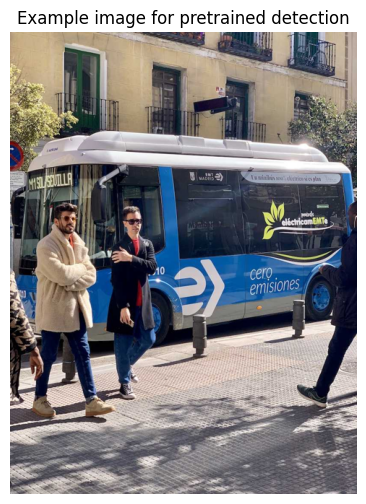

In [2]:
from pathlib import Path
from PIL import Image
from matplotlib.patches import Rectangle
from torch import nn
from torchvision import ops
import pandas as pd
import gc,re

root=Path.cwd()
if root.name=='notebooks': root=root.parent
image=Image.open(root/'data'/'detection_bus.jpg').convert('RGB').resize((480,640))
image_np=np.asarray(image)
print('RGB image:',image_np.shape,image_np.dtype)
plt.figure(figsize=(5,6)); plt.imshow(image); plt.axis('off'); plt.title('Example image for pretrained detection'); plt.show()

## ۳. قرارداد کادر و IoU

در xyxy، کادر برابر `(x_min,y_min,x_max,y_max)` است. بعضی مدل‌های TensorFlow خروجی `(y_min,x_min,y_max,x_max)`
نرمال‌شده در صفر تا یک دارند. قبل از رسم یا NMS باید قرارداد را درست تبدیل کنیم.

$$IoU(A,B)=\frac{Area(A\cap B)}{Area(A\cup B)}.$$

IoU صفر یعنی بدون همپوشانی و یک یعنی کادرها برابرند.

IoU of first two boxes: 0.7567568


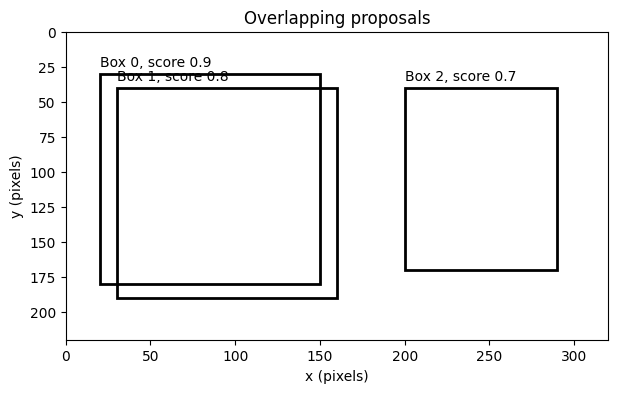

In [3]:
def iou(a,b):
    left,top=np.maximum(a[:2],b[:2])
    right,bottom=np.minimum(a[2:],b[2:])
    intersection=max(0,right-left)*max(0,bottom-top)
    area_a=(a[2]-a[0])*(a[3]-a[1])
    area_b=(b[2]-b[0])*(b[3]-b[1])
    return intersection/(area_a+area_b-intersection)
boxes=np.array([[20,30,150,180],[30,40,160,190],[200,40,290,170]],dtype='float32')
scores=np.array([0.9,0.8,0.7],dtype='float32')
print('IoU of first two boxes:',iou(boxes[0],boxes[1]))
fig,ax=plt.subplots(figsize=(7,4)); ax.set(xlim=(0,320),ylim=(220,0),xlabel='x (pixels)',ylabel='y (pixels)',title='Overlapping proposals')
for i,(x1,y1,x2,y2) in enumerate(boxes):
    ax.add_patch(Rectangle((x1,y1),x2-x1,y2-y1,fill=False,linewidth=2))
    ax.text(x1,y1-5,f'Box {i}, score {scores[i]:.1f}')
plt.show()

## ۴. NMS؛ حذف کادرهای تکراری

کادر دارای امتیاز بیشتر نگه داشته می‌شود و کادرهای بسیار همپوشانِ همان کلاس کنار می‌روند.
در مثال پایین همهٔ کادرها یک کلاس فرض شده‌اند. در تشخیص چندکلاسه معمولاً NMS برای هر کلاس یا گونهٔ class-aware استفاده می‌شود.
آستانهٔ score با آستانهٔ IoU دو پارامتر متفاوت‌اند.

In [4]:
keep_tf=tf.image.non_max_suppression(boxes[:,[1,0,3,2]],scores,max_output_size=10,iou_threshold=0.5).numpy()
keep_pt=ops.nms(torch.from_numpy(boxes),torch.from_numpy(scores),iou_threshold=0.5).numpy()
print('TF kept indices:',keep_tf)
print('Torch kept indices:',keep_pt)
np.testing.assert_array_equal(keep_tf,keep_pt)

TF kept indices: [0 2]
Torch kept indices: [0 2]


## ۵. R-CNN؛ CNN روی هر proposal

در مسیر اصلی، ابتدا ناحیه‌ها پیشنهاد می‌شوند و هر ناحیه جدا resize و وارد CNN می‌شود.
اینجا برای روشن‌بودن مثال سه کادر دستی می‌گذاریم؛ این‌ها ground truth یا خروجی Selective Search نیستند.
CNN کوچک این بخش **آموزش ندیده** است و فقط شکل محاسبه را نشان می‌دهد؛ classifier و SVM اصلی مقاله را بازسازی نمی‌کند.
هزینهٔ مهم این روش تکرار CNN برای تعداد زیادی proposal است.

R-CNN-style: CNN input batch has one image per proposal:

 (3, 64, 64, 3)
TF crop features: (3, 16, 16, 32) Torch: torch.Size([3, 32, 16, 16])


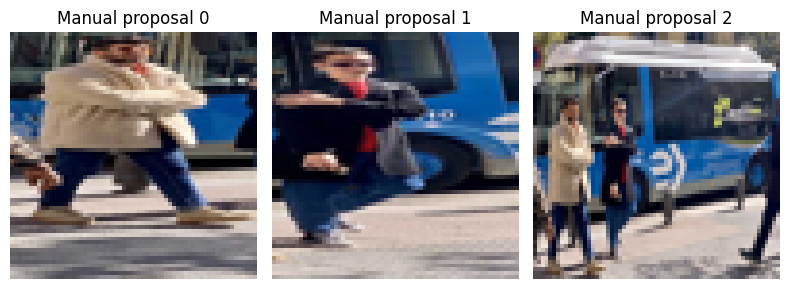

In [5]:
proposals=np.array([[20,230,145,620],[140,220,240,550],[5,130,475,540]],dtype='float32')
crops=np.stack([np.asarray(image.crop(tuple(box)).resize((64,64))) for box in proposals])/255.
crops=crops.astype('float32')
features_tf=tf.keras.Sequential([
    tf.keras.layers.Input((None,None,3)),tf.keras.layers.Conv2D(16,3,strides=2,padding='same',activation='relu'),
    tf.keras.layers.Conv2D(32,3,strides=2,padding='same',activation='relu')])
features_pt=nn.Sequential(nn.Conv2d(3,16,3,stride=2,padding=1),nn.ReLU(),nn.Conv2d(16,32,3,stride=2,padding=1),nn.ReLU())
crop_features_tf=features_tf(crops)
crop_features_pt=features_pt(torch.from_numpy(crops.transpose(0,3,1,2).copy()))
print('R-CNN-style: CNN input batch has one image per proposal:',crops.shape)
print('TF crop features:',crop_features_tf.shape,'Torch:',crop_features_pt.shape)
fig,axes=plt.subplots(1,3,figsize=(8,3))
for i,ax in enumerate(axes): ax.imshow(crops[i]); ax.set_title('Manual proposal '+str(i)); ax.axis('off')
plt.tight_layout(); plt.show()

## ۶. Fast R-CNN؛ اشتراک CNN و RoI pooling

کل تصویر یک بار به CNN داده می‌شود. هر proposal از روی feature map به خروجی با اندازهٔ ثابت تبدیل می‌شود.
RoI pooling اصلی ناحیه را به چند bin تقسیم و در هر bin max می‌گیرد؛ با RoIAlign یکسان نیست.
سپس دو head داریم: کلاس ناحیه و اصلاح مختصات کادر.
تابع کوچک TensorFlow زیر همین الگوی max pooling را نشان می‌دهد؛ قرارداد گردکردن آن نسخهٔ آموزشی است.
در این نمونه head کادر چهار خروجی مشترک برای کلاس‌ها دارد؛ این ساده‌سازی را با headهای وابسته به کلاسِ مقاله اشتباه نگیرید.

In [6]:
full_tf=features_tf(tf.constant(image_np[None]/255.,dtype=tf.float32))
full_pt=features_pt(torch.tensor(image_np.transpose(2,0,1).copy()[None],dtype=torch.float32)/255.)
print('Shared feature maps:',full_tf.shape,full_pt.shape)

def roi_pool_tf(feature_map,boxes,size=2):
    height,width=feature_map.shape[1:3]
    result=[]
    for x1,y1,x2,y2 in boxes:
        xs=np.linspace(x1/480*width,x2/480*width,size+1)
        ys=np.linspace(y1/640*height,y2/640*height,size+1)
        bins=[]
        for i in range(size):
            row=[]
            for j in range(size):
                crop=feature_map[0,int(np.floor(ys[i])):max(int(np.ceil(ys[i+1])),int(np.floor(ys[i]))+1),
                                  int(np.floor(xs[j])):max(int(np.ceil(xs[j+1])),int(np.floor(xs[j]))+1),:]
                row.append(tf.reduce_max(crop,axis=(0,1)))
            bins.append(tf.stack(row))
        result.append(tf.stack(bins))
    return tf.stack(result)

rois_tf=roi_pool_tf(full_tf,proposals)
rois_pt=ops.roi_pool(full_pt,[torch.from_numpy(proposals)],output_size=(2,2),spatial_scale=0.25)
head_classes_tf=tf.keras.layers.Dense(3)(tf.reshape(rois_tf,(3,-1)))
head_boxes_tf=tf.keras.layers.Dense(4)(tf.reshape(rois_tf,(3,-1)))
head_classes_pt=nn.Linear(32*2*2,3)(rois_pt.flatten(1))
head_boxes_pt=nn.Linear(32*2*2,4)(rois_pt.flatten(1))
print('TF RoIs / class logits / box deltas:',rois_tf.shape,head_classes_tf.shape,head_boxes_tf.shape)
print('Torch RoIs / class logits / box deltas:',rois_pt.shape,head_classes_pt.shape,head_boxes_pt.shape)

Shared feature maps: (1, 160, 120, 32) torch.Size([1, 32, 160, 120])
TF RoIs / class logits / box deltas: (3, 2, 2, 32) (3, 3) (3, 4)
Torch RoIs / class logits / box deltas: torch.Size([3, 32, 2, 2]) torch.Size([3, 3]) torch.Size([3, 4])


## ۷. Faster R-CNN و RPN

RPN از همان feature map برای هر مکان چند anchor را بررسی می‌کند: آیا شیء وجود دارد و کادر چگونه اصلاح شود؟
بعد از انتخاب proposalها، مرحلهٔ تشخیص ناحیه انجام می‌شود؛ به همین علت خانوادهٔ two-stage است.
مثال زیر خروجی RPN با سه anchor در هر مکان را نشان می‌دهد؛ هنوز خروجی detector آموزش‌دیده نیست.

$$L=L_{objectness}+\lambda L_{box}.$$

در head ناحیه نیز loss طبقه‌بندی و مکان‌یابی داریم. ضرایب و روش نمونه‌گیری در نسخه‌های عملی اهمیت دارند.

In [7]:
A=3
rpn_shared_tf=tf.keras.layers.Conv2D(16,3,padding='same',activation='relu')(full_tf)
objectness_tf=tf.keras.layers.Conv2D(A,1)(rpn_shared_tf)
offsets_tf=tf.keras.layers.Conv2D(4*A,1)(rpn_shared_tf)
rpn_shared_pt=nn.Sequential(nn.Conv2d(32,16,3,padding=1),nn.ReLU())(full_pt)
objectness_pt=nn.Conv2d(16,A,1)(rpn_shared_pt)
offsets_pt=nn.Conv2d(16,4*A,1)(rpn_shared_pt)
print('TF RPN objectness / offsets:',objectness_tf.shape,offsets_tf.shape)
print('Torch RPN objectness / offsets:',objectness_pt.shape,offsets_pt.shape)

TF RPN objectness / offsets: (1, 160, 120, 3) (1, 160, 120, 12)
Torch RPN objectness / offsets: torch.Size([1, 3, 160, 120]) torch.Size([1, 12, 160, 120])


## ۸. رسم خروجی مدل‌های واقعی

برای مقایسهٔ دیداری از یک عکس یکسان استفاده می‌کنیم، ولی مدل‌ها و وزن‌ها و کلاس‌های آموزشی یکسان نیستند.
از این مثال نمی‌توان برتری دقت یا سرعت خانواده‌ها را نتیجه گرفت. فقط شیوهٔ استفاده و قرارداد خروجی را می‌بینیم.

In [8]:
def show_detections(picture,boxes,labels,scores,title,threshold=0.4):
    fig,ax=plt.subplots(figsize=(6,7)); ax.imshow(picture); ax.axis('off'); ax.set_title(title)
    shown=0
    for box,label,score in zip(boxes,labels,scores):
        if score<threshold: continue
        x1,y1,x2,y2=box
        ax.add_patch(Rectangle((x1,y1),x2-x1,y2-y1,fill=False,edgecolor='lime',linewidth=2))
        ax.text(x1,max(12,y1),f'{label} {score:.2f}',color='black',fontsize=8,bbox={'facecolor':'white','alpha':.8,'pad':1})
        shown+=1
    plt.show(); print('Detections above threshold:',shown)

label_text=(root/'data'/'mscoco_label_map.pbtxt').read_text(encoding='utf-8')
coco_names={int(i):name for i,name in re.findall(r'id:\s*(\d+).*?display_name:\s*"([^"]+)"',label_text,re.S)}
# Some official versions use single quotes in the protobuf text.
if not coco_names:
    coco_names={int(i):name for i,name in re.findall(r'id:\s*(\d+).*?display_name:\s*\'([^\']+)\'',label_text,re.S)}
print('COCO label names:',len(coco_names))

COCO label names: 80


## ۹. Faster R-CNN آماده در PyTorch

Torchvision نسخهٔ سبک MobileNetV3 با ورودی کوتاه ۳۲۰ دارد. ورودی لیستی از تنسورهای RGB با شکل CHW و مقیاس صفر تا یک است.
خروجی boxes به صورت xyxy و در واحد پیکسل تصویر ورودی است.

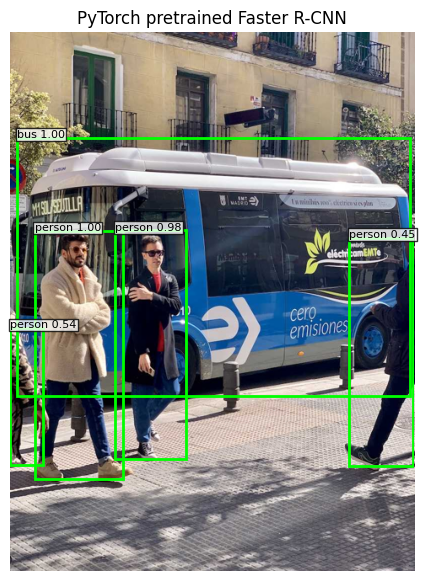

Detections above threshold: 5


In [9]:
from torchvision.models.detection import fasterrcnn_mobilenet_v3_large_320_fpn,FasterRCNN_MobileNet_V3_Large_320_FPN_Weights
weights_faster=FasterRCNN_MobileNet_V3_Large_320_FPN_Weights.DEFAULT
faster_pt=fasterrcnn_mobilenet_v3_large_320_fpn(weights=weights_faster).eval()
input_pt=torch.tensor(image_np.transpose(2,0,1).copy(),dtype=torch.float32)/255.
with torch.no_grad(): detection_pt=faster_pt([input_pt])[0]
show_detections(image,detection_pt['boxes'].numpy(),
    [weights_faster.meta['categories'][int(i)] for i in detection_pt['labels']],
    detection_pt['scores'].numpy(),'PyTorch pretrained Faster R-CNN')
del faster_pt; _=gc.collect()

## ۱۰. مدل‌های TensorFlow با SavedModel

وزن‌های رسمی TensorFlow را از Model Zoo یا انتشار رسمی TF Hub در Kaggle دریافت و از cache بارگذاری می‌کنیم.
برای inference به نصب کل Object Detection API نیاز نداریم. ورودی uint8 در مقیاس ۰ تا ۲۵۵ است.
این تابع فقط دریافت و بارگذاری مدل آماده را کوتاه می‌کند؛ محاسبهٔ مدل در خود SavedModel انجام می‌شود.

In [10]:
def load_detector_tf(name):
    if name.startswith('faster_rcnn'):
        import kagglehub
        path=kagglehub.model_download('tensorflow/faster-rcnn-resnet-v1/tensorFlow2/faster-rcnn-resnet50-v1-640x640/1')
        return tf.saved_model.load(path)
    url='https://storage.googleapis.com/download.tensorflow.org/models/object_detection/tf2/20200711/'+name+'.tar.gz'
    extracted=tf.keras.utils.get_file(fname=name+'.tar.gz',origin=url,extract=True)
    files=list(Path(extracted).rglob('saved_model.pb'))
    if not files: raise FileNotFoundError('SavedModel was not found in the extracted model archive.')
    return tf.saved_model.load(str(files[0].parent))

def display_tf_output(detector,picture,title):
    array=np.asarray(picture)
    output=detector(tf.convert_to_tensor(array[None],dtype=tf.uint8))
    count=int(output['num_detections'][0])
    boxes=output['detection_boxes'][0,:count].numpy()[:,[1,0,3,2]]
    boxes=boxes*np.array([array.shape[1],array.shape[0],array.shape[1],array.shape[0]])
    labels=[coco_names.get(int(i),str(int(i))) for i in output['detection_classes'][0,:count].numpy()]
    show_detections(picture,boxes,labels,output['detection_scores'][0,:count].numpy(),title)
    print('TF box output shape:',output['detection_boxes'].shape)

In [11]:
RUN_TF_FASTER=False  # Enable only when the official weight source is available in your environment.
if RUN_TF_FASTER:
    faster_tf=load_detector_tf('faster_rcnn_resnet50_v1_640x640_coco17_tpu-8')
    display_tf_output(faster_tf,image,'TensorFlow pretrained Faster R-CNN')
    del faster_tf; _=gc.collect()
else:
    print('Optional full TF Faster R-CNN was not executed: its official weight source denied geographic access.')
    print('The TF RPN component and full PyTorch Faster R-CNN examples above were executed.')

Optional full TF Faster R-CNN was not executed: its official weight source denied geographic access.
The TF RPN component and full PyTorch Faster R-CNN examples above were executed.


## ۱۱. YOLO؛ یک مسیر متراکم

در YOLOv1 تصویر به grid تقسیم می‌شد و هر cell چند کادر و امتیاز پیش‌بینی می‌کرد.
در نسل‌های بعدی، طراحی head و anchor و loss تغییر کرده است؛ فرمول خروجی همهٔ نسل‌ها یکسان نیست.
در مثال‌های زیر از YOLOv8 آماده استفاده می‌کنیم.

در TensorFlow از KerasCV با وزن Pascal VOC شامل ۲۰ کلاس و در PyTorch از Ultralytics با وزن COCO استفاده می‌کنیم.
بنابراین نام و تعداد کلاس‌ها و اندازهٔ مدل متفاوت است. این بخش به دو وابستگی اختیاریِ درج‌شده در requirements-vision نیاز دارد.

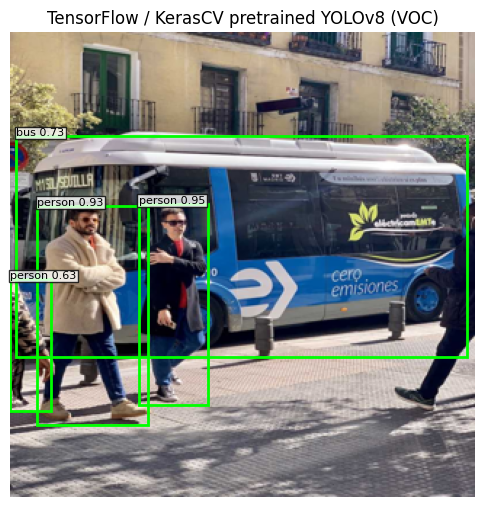

Detections above threshold: 4


In [12]:
import keras_cv
voc_names=['aeroplane','bicycle','bird','boat','bottle','bus','car','cat','chair','cow',
           'diningtable','dog','horse','motorbike','person','pottedplant','sheep','sofa','train','tvmonitor']
yolo_tf=keras_cv.models.YOLOV8Detector.from_preset('yolo_v8_m_pascalvoc',bounding_box_format='xyxy')
small_image=np.asarray(image.resize((320,320))).astype('float32')
yolo_result_tf=yolo_tf.predict(small_image[None],verbose=0)
classes=yolo_result_tf['classes'][0].astype(int)
names=[voc_names[i] if 0<=i<len(voc_names) else 'padding' for i in classes]
show_detections(Image.fromarray(small_image.astype('uint8')),yolo_result_tf['boxes'][0],names,
    yolo_result_tf['confidence'][0],'TensorFlow / KerasCV pretrained YOLOv8 (VOC)')
del yolo_tf; _=gc.collect()

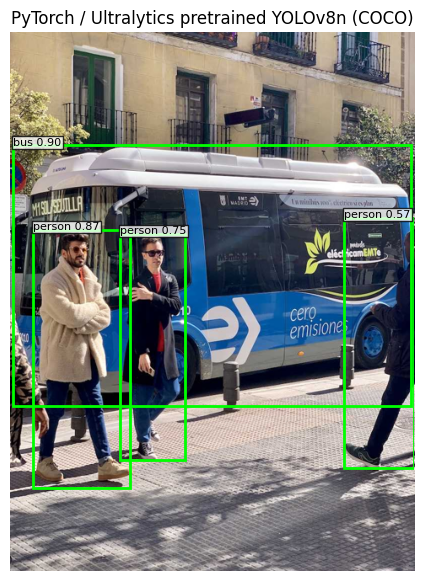

Detections above threshold: 4


In [13]:
from ultralytics import YOLO
yolo_path=Path.home()/'.cache'/'torch'/'hub'/'checkpoints'/'yolov8n.pt'
yolo_path.parent.mkdir(parents=True,exist_ok=True)
yolo_pt=YOLO(str(yolo_path))
yolo_result_pt=yolo_pt.predict(image,imgsz=320,device='cpu',verbose=False)[0]
show_detections(image,yolo_result_pt.boxes.xyxy.cpu().numpy(),
    [yolo_result_pt.names[int(i)] for i in yolo_result_pt.boxes.cls.cpu().numpy()],
    yolo_result_pt.boxes.conf.cpu().numpy(),'PyTorch / Ultralytics pretrained YOLOv8n (COCO)')
del yolo_pt; _=gc.collect()

## ۱۲. SSD؛ پیش‌بینی در چند مقیاس

SSD از چند feature map با اندازه‌های متفاوت استفاده می‌کند؛ لایهٔ ریزتر برای بعضی اشیای کوچک و لایهٔ درشت‌تر برای بعضی اشیای بزرگ مناسب‌تر است.
برای هر مکان default boxهایی با شکل‌ها و اندازه‌های مختلف در نظر گرفته می‌شود و شبکه کلاس و offset آن‌ها را پیش‌بینی می‌کند.
SSD هم یک detector تک‌مرحله‌ای است. SSD اصلی VGG و مدل‌های سبک MobileNet این مثال، پیاده‌سازی یکسانی ندارند.

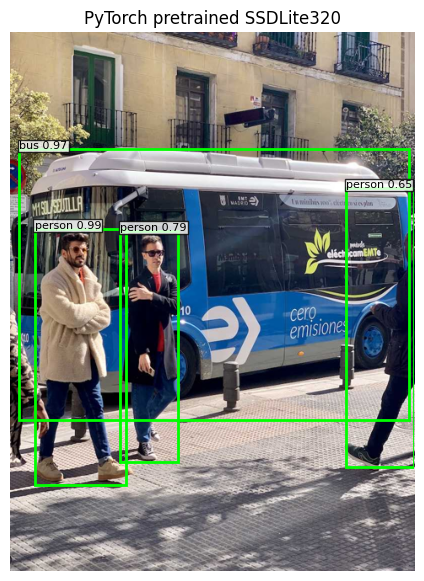

Detections above threshold: 4


In [14]:
from torchvision.models.detection import ssdlite320_mobilenet_v3_large,SSDLite320_MobileNet_V3_Large_Weights
weights_ssd=SSDLite320_MobileNet_V3_Large_Weights.DEFAULT
ssd_pt=ssdlite320_mobilenet_v3_large(weights=weights_ssd).eval()
with torch.no_grad(): ssd_result_pt=ssd_pt([input_pt])[0]
show_detections(image,ssd_result_pt['boxes'].numpy(),
    [weights_ssd.meta['categories'][int(i)] for i in ssd_result_pt['labels']],
    ssd_result_pt['scores'].numpy(),'PyTorch pretrained SSDLite320')
del ssd_pt; _=gc.collect()

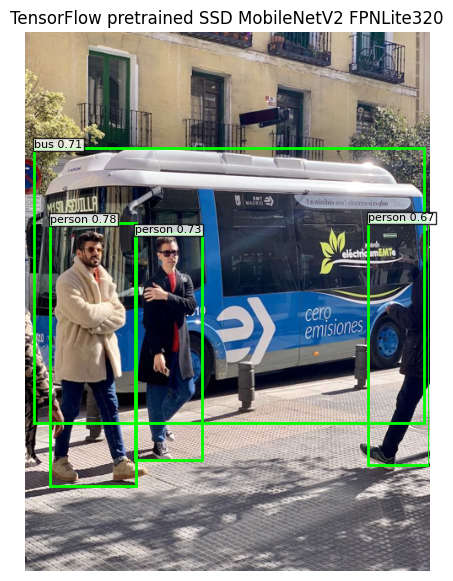

Detections above threshold: 4
TF box output shape: (1, 100, 4)


In [15]:
ssd_tf=load_detector_tf('ssd_mobilenet_v2_fpnlite_320x320_coco17_tpu-8')
display_tf_output(ssd_tf,image,'TensorFlow pretrained SSD MobileNetV2 FPNLite320')
del ssd_tf; _=gc.collect()

## ۱۳. اگر بخواهیم آموزش دهیم، برچسب چه شکلی است؟

برچسب فقط یک عدد برای کل عکس نیست؛ برای هر شیء کلاس و چهار مختصات لازم است.
در نمونهٔ Torchvision، کلاس صفر برای background است و کلاس‌های شیء از ۱ شروع می‌شوند.
KerasCV نمونه‌ای مانند دیکشنری images و bounding_boxes می‌گیرد و شمارهٔ کلاس‌ها از صفر شروع می‌شود.
دیکشنری‌های زیر فقط **شکل نمونهٔ برچسب فرضی** هستند، نه برچسب معتبر عکس اتوبوس و نه اجرای آموزش.

In [16]:
torch_target={'boxes':torch.tensor([[20.,30.,100.,200.]]),'labels':torch.tensor([1],dtype=torch.long)}
keras_cv_target={'images':tf.zeros((1,320,320,3)),
                 'bounding_boxes':{'boxes':tf.constant([[[20.,30.,100.,200.]]]),'classes':tf.constant([[0.]])}}
print('Torch target shapes:',{k:tuple(v.shape) for k,v in torch_target.items()})
print('KerasCV boxes shape:',keras_cv_target['bounding_boxes']['boxes'].shape)

Torch target shapes: {'boxes': (1, 4), 'labels': (1,)}
KerasCV boxes shape: (1, 1, 4)


## ۱۴. مقایسه و خواندن نتیجه

| روش | proposal از کجا؟ | CNN روی هر crop؟ | نکتهٔ آموزشی |
|---|---|---|---|
| R-CNN | روش خارجی مانند Selective Search | بله | تکرار محاسبه و آموزش چندمرحله‌ای |
| Fast R-CNN | روش خارجی | خیر، feature map مشترک | RoI pooling و head مشترک |
| Faster R-CNN | RPN آموختنی | خیر | proposal و تشخیص در یک سامانه |
| YOLO | پیش‌بینی متراکمِ خود مدل | خیر | خانوادهٔ یک‌مرحله‌ای با نسل‌های گوناگون |
| SSD | default box در چند مقیاس | خیر | تشخیص یک‌مرحله‌ای چندمقیاسی |

برای ارزیابی واقعی به چندین عکس دارای ground truth، تعریف IoU و معیارهایی مثل AP/mAP نیاز است.
یک عکس با کادرهای زیبا کافی نیست. threshold امتیاز را کم و زیاد کنید و تغییر false positive و missed detection را ببینید.
سرعت به نسخه، backbone، اندازهٔ ورودی، دستگاه و تنظیم اجرا بستگی دارد؛ نام خانواده به تنهایی یک عدد FPS ثابت نمی‌دهد.

**تمرین:** آستانهٔ نمایش را از ۰٫۴ به ۰٫۷ ببرید. سپس تفاوت Fast و Faster را در یک جمله با اشاره به RPN توضیح دهید.

## منابع رسمی


- [R-CNN](https://arxiv.org/abs/1311.2524)
- [Fast R-CNN](https://arxiv.org/abs/1504.08083)
- [Faster R-CNN](https://arxiv.org/abs/1506.01497)
- [YOLOv1](https://arxiv.org/abs/1506.02640)
- [SSD](https://arxiv.org/abs/1512.02325)
- [TensorFlow 2 Detection Model Zoo](https://github.com/tensorflow/models/blob/master/research/object_detection/g3doc/tf2_detection_zoo.md)
- [YOLOv8 در KerasCV](https://keras.io/examples/vision/yolov8/)
- [Ultralytics YOLOv8](https://docs.ultralytics.com/models/yolov8/)
- [مدل‌های تشخیص Torchvision](https://docs.pytorch.org/vision/0.24/models.html#object-detection)
- [عکس نمونهٔ اتوبوس، Ultralytics](https://github.com/ultralytics/ultralytics/tree/main/ultralytics/assets)


بازبینی منابع و اجرای این درس: ۱۶ اکتبر ۲۰۲۶.